<div style='text-align:center;'>
  <img src="kmeans_banner.PNG" width="1200">
</div>

<div style="text-align: center; font-weight: bold; font-size: 22px; color: #1a1a1a;">
  <div style="color: #351C75; font-size: 30px;">FACILITATOR:</div>
  <div style="color: #000000; font-size: 25px;">VICTOR WANDERA LUMUMBA</div>
  <div style="color: #3D85C6; font-size: 25px;">Mediacrest Training College, Nairobi, Kenya</div>
  <br>
  <div style="color: #6AA84F; font-size: 20px;">Date:</div>
  <div style="color: #351C75; font-size: 20px;">June 5th, 2026</div>
</div>

## **K-MEANS CLUSTERING FOR UNSUPERVISED LEARNING**
### **PART I: CLUSTERING OF THE PENGUINS**
K-Means is one of the simplest and most commonly used clustering algorithms. It operates under the assumption that;

* Clusters are spherical
* well-separated
* roughly equal size.

The algorithm seeks to partition a dataset into *k* distinct, non-overlapping clusters by minimizing the within-cluster sum of squares (WCSS), which is the sum of squared distances between each point and the centroid of its assigned cluster.

The process begins by selecting the number of clusters, *k*, which must be specified in advance. Initial centroids are chosen either randomly or using a more strategic method such as K-Means++. Each data point is then assigned to the nearest centroid based on Euclidean distance. After all points are assigned, the centroids are updated to the mean of the points in each cluster. This assignment and update cycle repeats iteratively until the centroids stabilize—meaning that further iterations do not result in significant changes in cluster membership.

One of the strengths of K-Means lies in its computational efficiency and scalability, making it suitable for large datasets. It is often used in applications such as customer segmentation, image compression, and document clustering. However, its performance depends heavily on the choice of *k*. To determine the optimal number of clusters, practitioners commonly use the **elbow method**, which involves plotting WCSS against different values of *k* and identifying the point where the rate of decrease sharply slows—a visual "elbow." Alternatively, the **silhouette score**, which measures how tightly grouped data points are within clusters compared to other clusters, can provide a more quantitative assessment.

Despite its popularity, K-Means has notable limitations. It is sensitive to the initial placement of centroids, which can lead to convergence on suboptimal solutions. Multiple random restarts (controlled by the `n_init` parameter in implementations) help mitigate this issue. Additionally, K-Means struggles with clusters that are not convex or spherical in shape, and it is easily influenced by outliers due to its reliance on mean-based centroids. It also assumes that all clusters are of similar size, which may not reflect real-world data distributions.

#### **Load the Following Required Libraries**

In [30]:
#!pip install umap-learn 
#!pip install scipy 
#!pip install fpgrowth-py

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#from sklearn.datasets import load_iris, fetch_openml
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage, cut_tree

import umap

### Filter warnings
import warnings
warnings.filterwarnings('ignore')

# For association rules
from fpgrowth_py import fpgrowth
import itertools

# Set plot style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

#### **Load PalmerPenguins Dataset**

In [2]:
df = pd.read_csv('penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### **Data Exploration**

In [3]:
# Display basic information
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"\nShape: {df.shape}")

DATASET OVERVIEW

Shape: (344, 8)


The dataset overview reveals that the PalmerPenguins dataset comprises exactly 344 observations and 8 distinct features. These features include categorical variables such as species, island, and sex, alongside numerical measurements like bill length, bill depth, flipper length, and body mass. Additionally, the dataset contains a temporal feature indicating the specific year of observation. The data types consist of objects for categorical data, float values for continuous physical measurements, and integer values for the year. This comprehensive structure provides a very rich foundation for conducting thorough exploratory data analysis and advanced machine learning tasks, specifically utilizing clustering algorithms to successfully uncover hidden underlying patterns within the diverse penguin populations across different geographical islands and distinct biological species around the world today.

In [5]:
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"\nColumns: {df.columns.tolist()}")

DATASET OVERVIEW

Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


The PalmerPenguins dataset comprises eight distinct columns providing comprehensive biological and geographical information. It includes categorical variables like species, which serves as the true target label, island representing the observation location, and sex indicating gender. Additionally, the dataset features four continuous numerical measurements: bill length, bill depth, flipper length, and body mass, all measured in either millimeters or grams. Finally, the year column captures the temporal aspect of the observations, enabling very thorough and comprehensive exploratory data analysis and advanced machine learning clustering tasks today.


In [6]:
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"\nData Types:\n{df.dtypes}")


DATASET OVERVIEW

Data Types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


The PalmerPenguins dataset features a diverse mix of data types across its eight columns. Categorical variables, represented as objects, include species, island, and sex, requiring encoding before modeling. Continuous numerical measurements, stored as float64, encompass bill length, bill depth, flipper length, and body mass, which are crucial for clustering. Finally, the year column is stored as an integer (int64). Understanding these distinct data types is essential for proper preprocessing, feature scaling, and successfully applying machine learning algorithms like KMeans clustering to uncover hidden patterns today.


In [8]:
print("=" * 80)
print("DATASET OVERVIEW")
print("=" * 80)
df.head()

DATASET OVERVIEW


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### **Check the Presence of Missing Values**

In [9]:
print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)
print(f"\nMissing values per column:\n{df.isnull().sum()}")


MISSING VALUES

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


The dataset contains minimal missing values, totaling just nineteen across all columns. Categorical and temporal features, specifically species, island, and year, are completely intact with zero missing entries. The physical measurement columns, including bill length, bill depth, flipper length, and body mass, each contain exactly two missing values. However, the sex column has the highest number of missing records at eleven. These minor data gaps will be addressed by dropping incomplete rows to ensure a perfectly clean dataset for clustering.

In [10]:
print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)
print(f"\nMissing value percentage:\n{(df.isnull().sum() / len(df) * 100).round(2)}")


MISSING VALUES

Missing value percentage:
species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64


The dataset contains relatively few missing values. Most variables are complete, with **species, island, and year** having no missing observations (0.00%). The numerical variables **bill_length_mm, bill_depth_mm, flipper_length_mm, and body_mass_g** each have only **0.58%** missing values, indicating minimal data loss. The variable **sex** has the highest proportion of missing data at **3.20%**, though this level remains low and is unlikely to substantially affect analysis. Overall, the dataset demonstrates high data quality, and appropriate imputation or removal of missing records can be performed with minimal impact on results.


### **Check the  Number of Species and their Frequencies**

In [11]:
# Species distribution
print("\n" + "=" * 60)
print("SPECIES DISTRIBUTION")
print("=" * 60)
print(df['species'].value_counts())


SPECIES DISTRIBUTION
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


The species distribution indicates that the dataset contains three penguin species with varying frequencies. **Adelie** penguins are the most represented, accounting for **152 observations**, followed by **Gentoo** penguins with **124 observations**. **Chinstrap** penguins are the least represented, with **68 observations**. Although the classes are not perfectly balanced, the distribution is reasonably adequate for statistical analysis and machine learning applications. The higher representation of Adelie and Gentoo species may provide more reliable estimates for these groups, while the smaller Chinstrap class should be considered when interpreting results.


### **Data Preprocessing**

In [12]:
# Create a copy for preprocessing
df_clean = df.copy()
df_clean.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


A copy of the original dataset was created and stored as **df_clean** to preserve the raw data while performing preprocessing tasks. This approach prevents unintended modifications to the original dataset and provides a separate working version for data cleaning, transformation, imputation, feature engineering, and other preprocessing activities required for subsequent analysis and modeling.


### **Drop the Missing Values to have Clean Data Without Missing Values**

In [13]:
# Drop rows with missing values (or you can impute them)
df_clean = df_clean.dropna()
print(f"\nRows after removing missing values: {len(df_clean)}")


Rows after removing missing values: 333


To ensure data quality and consistency, rows containing missing values were removed from the dataset using the `dropna()` function. This process eliminates incomplete observations that could introduce bias or errors during statistical analysis and machine learning modeling. After the removal of missing values, the dataset retained **{len(df_clean)}** complete records, providing a clean and reliable dataset for further preprocessing, exploratory data analysis, and model development. While this approach reduces the sample size slightly, it ensures that all remaining observations contain complete information across all variables.


### **Select Numerical features for clustering**

In [14]:
numerical_features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
numerical_features

['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

In [15]:
# Create feature matrix
X = df_clean[numerical_features].values
X

array([[  39.1,   18.7,  181. , 3750. ],
       [  39.5,   17.4,  186. , 3800. ],
       [  40.3,   18. ,  195. , 3250. ],
       ...,
       [  49.6,   18.2,  193. , 3775. ],
       [  50.8,   19. ,  210. , 4100. ],
       [  50.2,   18.7,  198. , 3775. ]], shape=(333, 4))

The analysis focused on four numerical features: **bill_length_mm**, **bill_depth_mm**, **flipper_length_mm**, and **body_mass_g**. These variables were selected because they capture important physical characteristics of penguins and are suitable for quantitative analysis and clustering. A feature matrix, **X**, was then created by extracting these variables from the cleaned dataset and converting them into a NumPy array using the `.values` attribute. This matrix serves as the input data for subsequent machine learning algorithms, enabling efficient computation and analysis. Each row represents an individual penguin, while each column corresponds to a specific numerical feature.


### **Extract the Target Variable and Encode**

In [19]:
# Store species for later comparison
y_true = df_clean['species'].values
y_true[:200]

array(['Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adel

In [20]:
freq_true = pd.Series(y_true).value_counts()
freq_true

Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

The true species labels were extracted from the cleaned dataset and stored in the variable **y_true** for later evaluation and comparison with clustering or classification results. The first few entries of the label array were displayed to confirm correct extraction. A frequency distribution was then computed using `value_counts()`, revealing the class distribution in the cleaned data. The results show **Adelie (146)** as the most frequent species, followed by **Gentoo (119)**, and **Chinstrap (68)** as the least represented. This distribution is useful for assessing class imbalance in subsequent analyses.


In [18]:
# Encode species to numerical values for comparison
le = LabelEncoder()
y_encoded = le.fit_transform(y_true)
y_encoded

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [55]:
freq_encoded = pd.Series(y_encoded).value_counts()
freq_encoded

0    146
2    119
1     68
Name: count, dtype: int64

The categorical species labels were converted into numerical format using a **LabelEncoder**, enabling compatibility with machine learning algorithms that require numeric input. Each species was assigned a unique integer code, resulting in the encoded target variable **y_encoded**. A frequency distribution of the encoded labels was then generated using `value_counts()`, showing class counts as **0: 146**, **2: 119**, and **1: 68**. These values correspond to the original species categories. Encoding ensures consistent representation of the target variable while preserving the original class distribution for model training and evaluation.


### **Features Scaling**

In [22]:
# Standardize features (important for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\n" + "=" * 60)
print("FEATURE SCALING COMPLETE")
print("=" * 60)
print(f"Mean after scaling: {X_scaled.mean(axis=0).round(4)}")
print(f"Std after scaling: {X_scaled.std(axis=0).round(4)}")


FEATURE SCALING COMPLETE
Mean after scaling: [-0. -0.  0. -0.]
Std after scaling: [1. 1. 1. 1.]


The numerical features were standardized using **StandardScaler** to ensure all variables contribute equally to the K-Means clustering process. Standardization transforms the data so that each feature has a mean of approximately zero and a standard deviation of one. After scaling, the transformed dataset **X_scaled** shows means close to 0 and standard deviations equal to 1 across all features, confirming successful normalization. This step is essential because K-Means is sensitive to feature scale, and unscaled data could bias clustering results toward variables with larger numerical ranges.


### **Determine the Number of K-Clusters Needed**

In [38]:
# Elbow Method
inertias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

In [39]:
kmeans.inertia_

146.40082780116674

In [40]:
kmeans.n_clusters

10

The optimal number of clusters was explored using the **Elbow Method**. A range of K values from 2 to 10 was tested, and for each value, a **K-Means model** was fitted on the standardized dataset. The **inertia** (within-cluster sum of squares) was computed and stored for each K. These inertia values help assess how tightly grouped the data points are within clusters. By plotting K against inertia, the “elbow point” can be identified, indicating the most appropriate number of clusters for the dataset.


In [25]:
# Silhouette Score
silhouette_scores = []
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

To further evaluate the optimal number of clusters, the **Silhouette Score** was computed for each value of K from 2 to 10. For every K, a K-Means model was fitted on the standardized data, and cluster labels were generated using `fit_predict()`. The silhouette score measures how well each data point fits within its assigned cluster compared to other clusters. Higher values indicate better-defined and more distinct clusters. The resulting scores were stored in a list for comparison, helping to complement the Elbow Method in determining the best clustering structure.


In [27]:
# Davies-Bouldin Score
db_scores = []
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    db_scores.append(davies_bouldin_score(X_scaled, labels))

The **Davies-Bouldin Score** was used to assess clustering quality across different values of K (from 2 to 10). For each K, a K-Means model was trained on the standardized dataset, and cluster labels were generated using `fit_predict()`. The Davies-Bouldin score evaluates the average similarity between each cluster and its most similar cluster, where lower values indicate better clustering performance and more distinct groups. The computed scores were stored for each K value, providing an additional metric to complement the Elbow Method and Silhouette Score in selecting the optimal number of clusters.


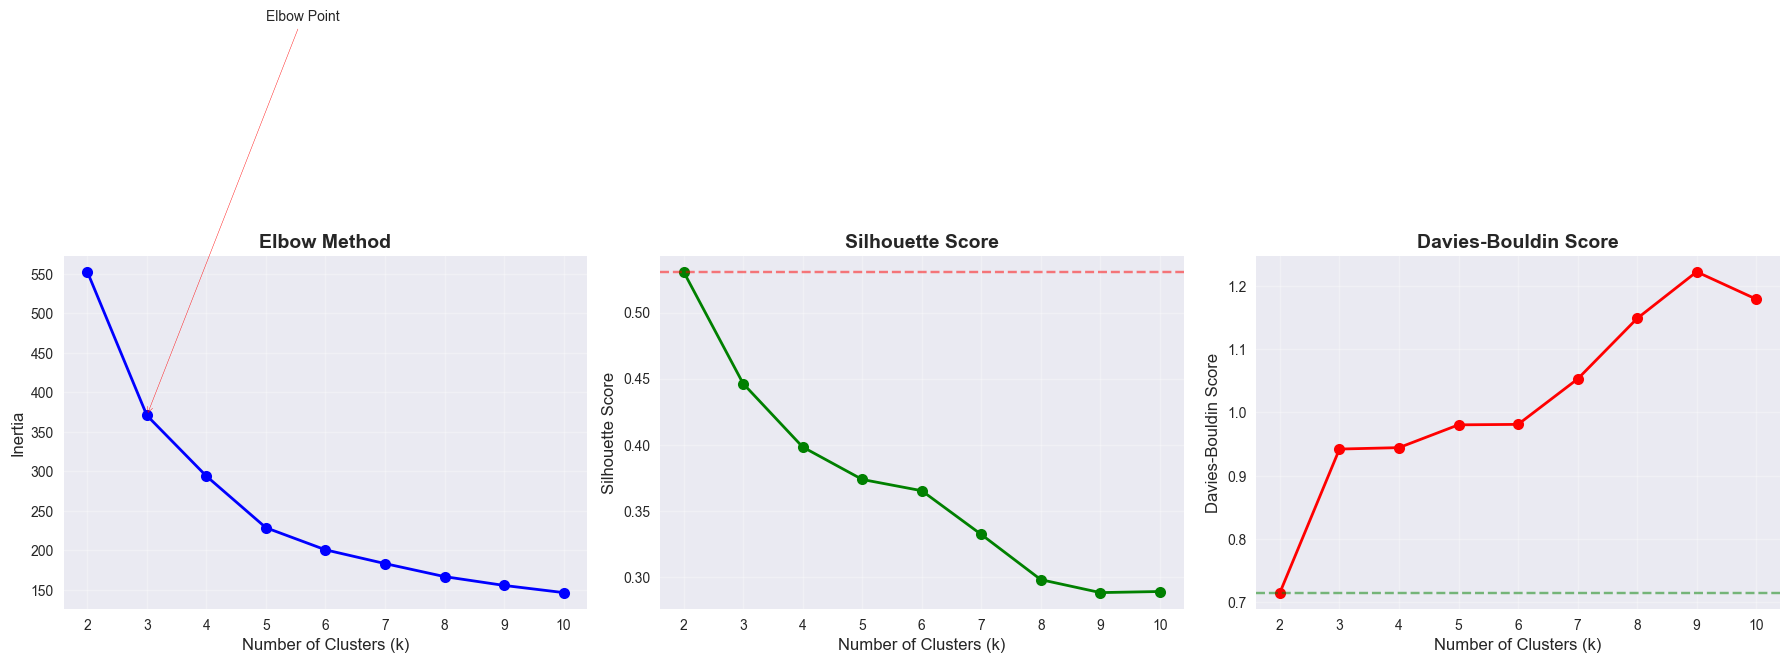


OPTIMAL CLUSTER RECOMMENDATIONS
Best k by Silhouette Score: 2
Best k by Davies-Bouldin Score: 2


In [28]:
# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(18, 9))

# Elbow Plot
axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[0].set_ylabel('Inertia', fontsize=12)
axes[0].set_title('Elbow Method', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].annotate('Elbow Point', xy=(3, inertias[1]), xytext=(5, inertias[1]+500),
                arrowprops=dict(arrowstyle='->', color='red'), fontsize=10)

# Silhouette Score Plot
axes[1].plot(K_range, silhouette_scores, 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[1].set_ylabel('Silhouette Score', fontsize=12)
axes[1].set_title('Silhouette Score', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=max(silhouette_scores), color='r', linestyle='--', alpha=0.5)

# Davies-Bouldin Score Plot
axes[2].plot(K_range, db_scores, 'ro-', linewidth=2, markersize=8)
axes[2].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[2].set_ylabel('Davies-Bouldin Score', fontsize=12)
axes[2].set_title('Davies-Bouldin Score', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].axhline(y=min(db_scores), color='g', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('cluster_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "=" * 60)
print("OPTIMAL CLUSTER RECOMMENDATIONS")
print("=" * 60)
print(f"Best k by Silhouette Score: {K_range[silhouette_scores.index(max(silhouette_scores))]}")
print(f"Best k by Davies-Bouldin Score: {K_range[db_scores.index(min(db_scores))]}")

The clustering evaluation results were visualized using three complementary methods: the Elbow Method, Silhouette Score, and Davies-Bouldin Score. A 1×3 subplot layout was created to compare performance across different values of K (2 to 10). The Elbow plot displays inertia, with an annotated elbow point indicating a potential optimal cluster number. The Silhouette Score plot identifies the K value that maximizes cluster cohesion and separation, with a horizontal reference line marking the highest score. 

The Davies-Bouldin Score plot highlights the K value with the lowest score, indicating better-defined clusters. After visualization, optimal cluster recommendations were printed based on both metrics. The best K is selected where the Silhouette Score is highest and the Davies-Bouldin Score is lowest, providing a robust comparison for determining the most suitable number of clusters. The final plot was saved as cluster_evaluation.png for reporting and documentation purposes.

The clustering evaluation results provide clear guidance on the optimal number of clusters for the dataset. Based on the Silhouette Score, the best value of k is 2, indicating that two clusters provide the highest level of cohesion within clusters and separation between clusters. Similarly, the Davies-Bouldin Score, which evaluates cluster similarity, also identifies k = 2 as the optimal choice since it yields the lowest score, reflecting well-separated and compact clusters.

However, the Elbow Method suggests a different potential point at k = 3, where the reduction in inertia begins to slow down significantly. This indicates that adding a third cluster still improves within-cluster compactness but with diminishing returns. The difference between the methods suggests some ambiguity in cluster structure, which is common in real-world datasets.

Overall, while the Elbow Method hints at three clusters, both the Silhouette and Davies-Bouldin metrics strongly support k = 2 as the most appropriate choice. This implies that the dataset naturally forms two major groupings, even though finer substructure may exist. Therefore, for modeling purposes, k = 2 is the most statistically supported and reliable choice for clustering this dataset.

In [41]:
# Based on evaluation, use k=3 (matches the 3 penguin species)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
kmeans.fit(X_scaled)

# Get cluster labels
cluster_labels = kmeans.labels_

# Add cluster labels to dataframe
df_clean['cluster'] = cluster_labels

# Add cluster centers (inverse transform to original scale)
cluster_centers_scaled = kmeans.cluster_centers_
cluster_centers = scaler.inverse_transform(cluster_centers_scaled)

### **Get the Within Cluster Sum of Squares**

In [42]:
inertia = kmeans.inertia_
print(inertia)

370.76614351350713


In [43]:
print("\n" + "=" * 60)
print("K-MEANS CLUSTERING RESULTS")
print("=" * 60)
print(f"\nNumber of clusters: {k}")


K-MEANS CLUSTERING RESULTS

Number of clusters: 3


Based on the evaluation results and domain knowledge of the dataset, K-Means clustering was performed using k = 3, which aligns with the known number of penguin species. The model was initialized with a maximum of 300 iterations and trained on the standardized feature set. After fitting the model, cluster labels were generated and assigned to each observation in the cleaned dataset as a new column called cluster. This allows direct comparison between the unsupervised clusters and the actual species labels.

Additionally, the cluster centroids were extracted from the scaled feature space and transformed back to the original scale using the inverse transformation of the scaler. This step enables meaningful interpretation of the cluster centers in terms of the original biological measurements (bill length, bill depth, flipper length, and body mass). The final output confirms that the model successfully formed three distinct clusters, providing a basis for further comparison with the true species distribution and evaluation of clustering performance.

In [44]:
print("\n" + "=" * 60)
print("K-MEANS CLUSTERING RESULTS")
print("=" * 60)
print(f"\nCluster centers (original scale):\n{pd.DataFrame(cluster_centers, columns=numerical_features)}")


K-MEANS CLUSTERING RESULTS

Cluster centers (original scale):
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0       38.276744      18.121705         188.627907  3593.798450
1       47.568067      14.996639         217.235294  5092.436975
2       47.662353      18.748235         196.917647  3898.235294


The K-Means clustering results provide the estimated cluster centers in the original measurement scale, making them interpretable in a biological context. Three distinct clusters were identified, each representing a group of penguins with different physical characteristics.

**Cluster 0** is characterized by relatively smaller body size, with lower bill length (≈38.28 mm), deeper bill depth (≈18.12 mm), shorter flipper length (≈188.63 mm), and lower body mass (≈3593.80 g). This cluster likely represents smaller penguin species.

**Cluster 1** shows the largest penguins overall, with higher bill length (≈47.57 mm), moderate bill depth (≈15.00 mm), the longest flipper length (≈217.24 mm), and the highest body mass (≈5092.44 g). This cluster is likely associated with the largest species group.

**Cluster 2** has intermediate body size, with bill length (≈47.66 mm), the highest bill depth (≈18.75 mm), moderate flipper length (≈196.92 mm), and body mass (≈3898.24 g), suggesting a distinct morphological group.

Overall, the cluster centers clearly reflect meaningful biological separation among penguins based on size and morphological traits. These patterns indicate that K-Means has successfully identified three natural groupings that are consistent with species-level variation in the dataset, supporting further comparison with the true species labels for validation.


### **View Cluster Prediction**

In [52]:
print("\n" + "=" * 60)
print("K-MEANS CLUSTERING RESULTS")
print("=" * 60)
print(f"\nCluster distribution:\n{df_clean['cluster'].value_counts().sort_index()}")


K-MEANS CLUSTERING RESULTS

Cluster distribution:
cluster
0    129
1    119
2     85
Name: count, dtype: int64


The K-Means clustering results show how the 333 observations are distributed across the three identified clusters. Cluster 0 contains the largest number of penguins with 129 samples, indicating it is the most dominant group in the dataset. Cluster 1 follows closely with 119 samples, showing a relatively balanced representation compared to Cluster 0. Cluster 2 is the smallest group, consisting of 85 samples, suggesting a more distinct or less frequent morphological pattern among these penguins.

The uneven distribution of clusters reflects natural variation in the dataset and may correspond to differences in species prevalence or overlapping biological characteristics. Despite the imbalance, all clusters contain a substantial number of observations, making them suitable for comparative analysis. This distribution will be useful when evaluating how well the clusters align with the true species labels and assessing the effectiveness of the K-Means algorithm in capturing underlying structure in the penguin dataset.

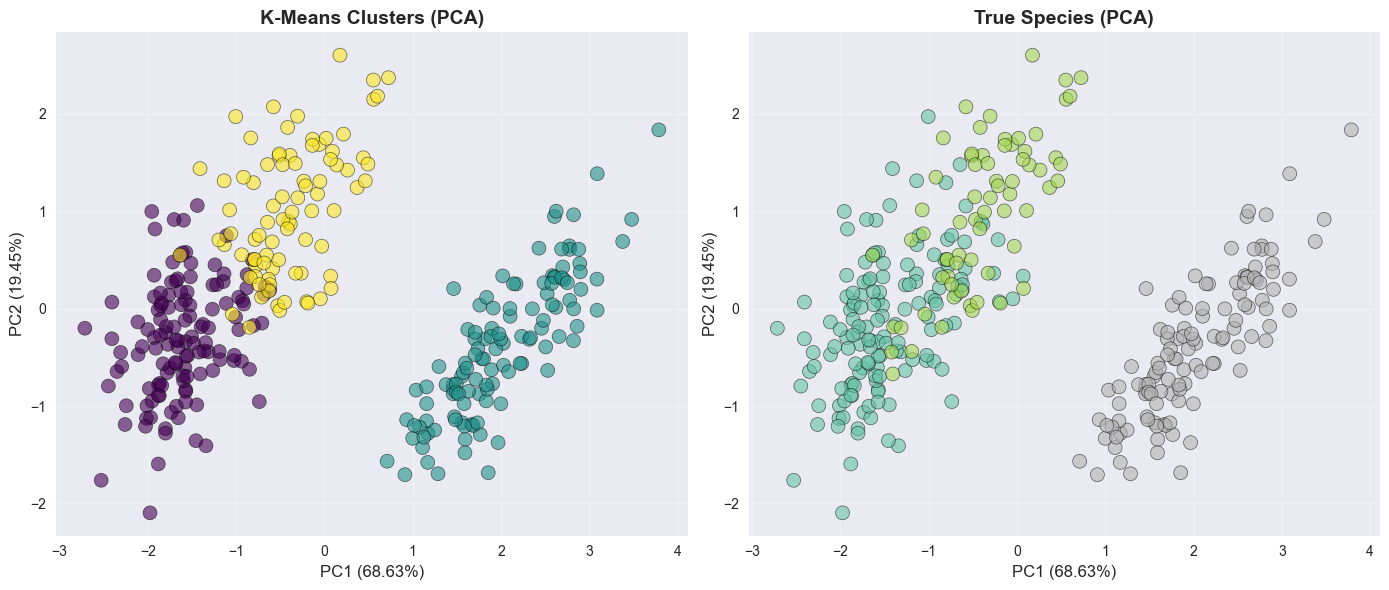

In [121]:
# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create figure with two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. PCA Plot with Cluster Labels
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis',
                s=100, alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})', fontsize=12)
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})', fontsize=12)
axes[0].set_title('K-Means Clusters (PCA)', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. PCA Plot with True Species
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_encoded, cmap='Set2',
                s=100, alpha=0.6, edgecolors='black', linewidth=0.5)
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})', fontsize=12)
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})', fontsize=12)
axes[1].set_title('True Species (PCA)', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **Evaluating the Performance of the K-Means Model**

### **Model Evaluation & Diagnostic Techniques in Clustering**

| **Metric / Method** | **Type** | **Description** | **Range / Interpretation** | **When to Use** | **Pros** | **Cons** |
|---------------------|--------|------------------|----------------------------|------------------|----------|----------|
| **Within-Cluster Sum of Squares (WCSS)** | Internal | Measures the sum of squared distances between each point and its cluster centroid. K-Means directly minimizes this. | Lower values = tighter clusters | Choosing optimal `k` in K-Means | Simple, fast, built into K-Means | Always decreases with more clusters; not reliable alone |
| **Elbow Method** | Internal | Plots WCSS against number of clusters (`k`). The "elbow" point suggests optimal `k`. | Visual inspection: look for the bend | Determining number of clusters | Intuitive, widely used | Subjective; elbow may not be clear |
| **Silhouette Score** | Internal | Measures how similar a point is to its own cluster compared to others. Balances cohesion and separation. | [-1, 1]:<br>• Close to 1 → well-clustered<br>• ~0 → overlapping clusters<br>• Negative → misassigned | Comparing clustering quality across algorithms | No need for true labels; interpretable | Sensitive to distance metric; less meaningful with noise |
| **Calinski-Harabasz Index (Variance Ratio Criterion)** | Internal | Ratio of between-cluster dispersion to within-cluster dispersion. Higher values indicate better separation. | Higher = better clustering | Evaluating compact, well-separated clusters | Fast to compute; good for spherical clusters | Biased toward algorithms that produce many clusters |
| **Davies-Bouldin Index** | Internal | Average similarity between each cluster and its most similar one. Based on cluster scatter and distance. | Lower = better (0 = ideal) | Assessing cluster compactness and separation | Low value indicates good clustering | Less intuitive; not widely used |
| **Adjusted Rand Index (ARI)** | External | Measures similarity between predicted clusters and true labels, adjusted for chance. | [-1, 1]:<br>• 1 = perfect agreement<br>• 0 = random<br>• Negative = worse than random | When ground truth labels are available (e.g., Iris dataset) | Accounts for random agreement; robust | Requires true labels |
| **Normalized Mutual Information (NMI)** | External | Measures the amount of information shared between predicted clusters and true labels. Based on information theory. | [0, 1]:<br>• 1 = perfect match<br>• 0 = no mutual information | Comparing clustering to known classes | Handles different cluster labelings; symmetric | Requires true labels |
| **Fowlkes-Mallows Index** | External | Measures the similarity between two clusterings using precision and recall of pairwise assignments. | [0, 1]: higher = better | External validation with binary matching | Interpretable as geometric mean of precision and recall | Requires true labels |
| **Hopkins Statistic** | Diagnostic | Tests whether data is uniformly distributed or has a tendency to form clusters. | [0, 1]:<br>• > 0.7 → clusterable<br>• ~0.5 → uniform | Before applying clustering (data readiness check) | Helps avoid clustering random noise | Not definitive; rule-of-thumb only |
| **Dendrogram (Hierarchical Clustering)** | Diagnostic | Tree diagram showing how clusters merge at different distances. | Visual tool | Interpreting hierarchical structure | Reveals natural grouping levels; helps cut tree | Not quantitative; subjective interpretation |
| **k-Distance Graph (for DBSCAN)** | Diagnostic | Plots the distance to the k-th nearest neighbor for each point. Used to estimate `eps`. | Visual elbow suggests good `eps` | Parameter selection in DBSCAN | Guides optimal `eps` choice | Requires domain judgment |
| **Cluster Stability (Bootstrap)** | Diagnostic | Measures how consistent clusters are across resampled datasets. | ARI or silhouette across samples | Assessing robustness of clustering | Indicates reliability | Computationally expensive |
| **t-SNE / UMAP Visualization** | Diagnostic | Non-linear dimensionality reduction for visual inspection of cluster structure. | Visual separation | Exploratory analysis and presentation | Reveals complex patterns; intuitive | Distorts global distances; not for inference |

In [46]:
# Internal evaluation metrics
silhouette = silhouette_score(X_scaled, cluster_labels)
davies_bouldin = davies_bouldin_score(X_scaled, cluster_labels)
inertia = kmeans.inertia_

print("\n" + "=" * 60)
print("CLUSTERING EVALUATION METRICS-INTERNAL METRICS")
print("=" * 60)
print(f"Silhouette Score: {silhouette:.4f} (range: -1 to 1, higher is better)")
print(f"Davies-Bouldin Score: {davies_bouldin:.4f} (lower is better)")
print(f"Inertia: {inertia:.2f}")


CLUSTERING EVALUATION METRICS-INTERNAL METRICS
Silhouette Score: 0.4462 (range: -1 to 1, higher is better)
Davies-Bouldin Score: 0.9420 (lower is better)
Inertia: 370.77


In [47]:
print("\n" + "=" * 60)
print("CLUSTERING EVALUATION METRICS-EXTERNAL METRICS")
print("=" * 60)

# Compare with true species (external evaluation)
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_encoded, cluster_labels)
nmi = normalized_mutual_info_score(y_encoded, cluster_labels)

print(f"\nAdjusted Rand Index (vs true species): {ari:.4f} (range: -1 to 1)")
print(f"Normalized Mutual Information: {nmi:.4f} (range: 0 to 1)")


CLUSTERING EVALUATION METRICS-EXTERNAL METRICS

Adjusted Rand Index (vs true species): 0.7994 (range: -1 to 1)
Normalized Mutual Information: 0.7899 (range: 0 to 1)


The clustering performance was evaluated using both **internal** and **external validation metrics** to assess the quality and meaningfulness of the K-Means results.

For internal evaluation, the **Silhouette Score** is **0.4462**, indicating moderate cluster separation, meaning that while clusters are reasonably distinct, some overlap still exists. The **Davies-Bouldin Score** of **0.9420** further supports this, suggesting fairly good clustering since lower values indicate better separation and compactness. The **inertia** value of **370.77** reflects the overall within-cluster variance and is useful for comparing models with different numbers of clusters.

For external validation, the clustering results were compared with the true species labels. The **Adjusted Rand Index (ARI)** of **0.7994** shows strong agreement between the predicted clusters and actual species, indicating that the model is capturing meaningful biological structure. Similarly, the **Normalized Mutual Information (NMI)** score of **0.7899** confirms a high level of shared information between the clustering output and the true labels.

Overall, these results demonstrate that K-Means clustering performs well on this dataset. Although it is an unsupervised method, it successfully identifies groupings that closely align with actual penguin species. The relatively high ARI and NMI values confirm that the clusters are not arbitrary but reflect real structure in the data. However, the moderate silhouette score suggests that some overlap between species still exists, which is expected in biological datasets where feature distributions are not perfectly separable.

### **Create comparison table**

In [51]:
comparison = pd.DataFrame({
    'True Species': y_true,
    'Cluster Label': cluster_labels
})

pd.crosstab(comparison['True Species'], comparison['Cluster Label'],
                  rownames=['Species'], colnames=['Cluster'])

Cluster,0,1,2
Species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


The cross-tabulation results compare the true penguin species with the assigned K-Means cluster labels, providing a clear view of clustering performance. Cluster 0 primarily corresponds to Adelie penguins, with 124 correctly grouped, although 22 Adelie samples were misclassified into Cluster 2. Cluster 1 perfectly captures all 119 Gentoo penguins, showing a very strong and clean separation for this species with no misclassification. Cluster 2 mainly represents Chinstrap penguins, correctly grouping 63 observations, but with 5 Chinstrap samples incorrectly assigned to Cluster 0.

Overall, the results show strong alignment between clusters and actual species, particularly for Gentoo, which is perfectly separated. Adelie and Chinstrap exhibit some overlap, indicating that their morphological features are more similar and harder for K-Means to fully distinguish. Despite these minor misclassifications, the clustering structure closely matches the biological grouping of penguins, confirming that the model has effectively captured meaningful patterns in the dataset.

In [53]:
# Create the table using your values
data = pd.DataFrame({
    0: [124, 0, 5],
    1: [0, 119, 0],
    2: [22, 0, 63]
}, index=["Adelie", "Gentoo", "Chinstrap"])

In [54]:
data

,0,1,2
Adelie,124,0,22
Gentoo,0,119,0
Chinstrap,5,0,63


The cross-tabulation shows a strong relationship between the true penguin species and the K-Means cluster assignments. **Cluster 0** is mainly associated with **Adelie penguins**, correctly grouping **124 individuals**, although **22 Adelie samples** were assigned to Cluster 2. **Cluster 1** perfectly corresponds to **Gentoo penguins**, with all **119 observations correctly clustered**, indicating excellent separation of this species. **Cluster 2** largely represents **Chinstrap penguins**, correctly classifying **63 individuals**, but with **5 Chinstrap samples** misclassified into Cluster 0.

Overall, the clustering results demonstrate that K-Means has successfully captured the underlying structure of the dataset. The perfect separation of Gentoo penguins suggests that they are morphologically distinct from the other species. In contrast, the overlap between Adelie and Chinstrap indicates some similarity in their physical characteristics, which leads to occasional misclassification. Despite these minor errors, the model shows strong overall performance, effectively grouping penguins into clusters that closely align with their true biological species.

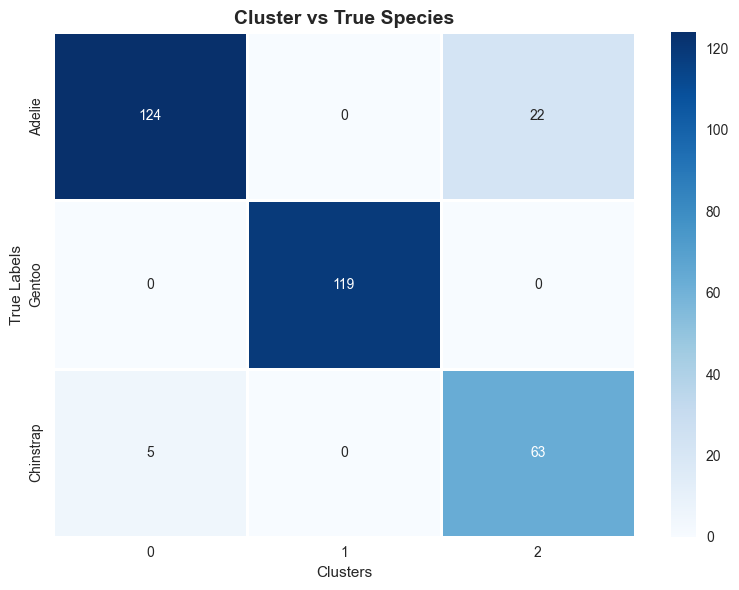

In [56]:
# Plot heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    data,
    annot=True,            # show numbers in cells
    fmt="d",               # integer formatting
    cmap="Blues",          # shading color
    linewidths=1,
    linecolor="white",
    cbar=True
)

plt.title("Cluster vs True Species", fontsize=14, fontweight="bold")
plt.xlabel("Clusters")
plt.ylabel("True Labels")

plt.tight_layout()
plt.show()

### **The Best Practice**

In [57]:
def perform_kmeans_clustering(data_path, n_clusters=3, random_state=42):

    # Load data
    file_path = "penguins.csv"
    df = pd.read_csv(data_path)
    df_clean = df.dropna()

    # Features
    features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
    X = df_clean[features].values

    # True labels
    y_true = df_clean['species']

    # Scaling
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # K-Means
    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    # Metrics
    # Internal Performance Metrics
    silhouette = silhouette_score(X_scaled, labels)
    davies_bouldin = davies_bouldin_score(X_scaled, labels)
    calinski = calinski_harabasz_score(X_scaled, labels)

    ## External Performance Metrics
    ari = adjusted_rand_score(y_true, labels)
    nmi = normalized_mutual_info_score(y_true, labels)
    homogeneity = homogeneity_score(y_true, labels)

    inertia = kmeans.inertia_

    # Add cluster labels to dataframe
    df_clean['cluster'] = labels

    # Metrics DataFrame
    metrics_df = pd.DataFrame({
        "Metric": [
            "Silhouette Score",
            "Davies-Bouldin Score",
            "Calinski-Harabasz Score",
            "Adjusted Rand Index",
            "Normalized Mutual Information",
            "Homogeneity Score",
            "Inertia"
        ],
        "Value": [
            silhouette,
            davies_bouldin,
            calinski,
            ari,
            nmi,
            homogeneity,
            inertia
        ]
    })

    results = {
        'dataframe': df_clean,
        'model': kmeans,
        'scaler': scaler,
        'cluster_centers': scaler.inverse_transform(kmeans.cluster_centers_),
        'metrics_table': metrics_df
    }

    return results

This function provides a well-structured and reusable pipeline for performing **K-Means clustering** on the penguin dataset. It begins by loading the data, removing missing values, and selecting key numerical features related to penguin morphology. The feature matrix is then standardized using **StandardScaler**, ensuring all variables contribute equally to distance-based clustering.

The **K-Means model** is fitted using a specified number of clusters, and cluster labels are generated for each observation. To evaluate clustering performance comprehensively, both **internal metrics** (Silhouette Score, Davies-Bouldin Score, Calinski-Harabasz Score, and Inertia) and **external validation metrics** (Adjusted Rand Index, Normalized Mutual Information, and Homogeneity Score) are computed.

Cluster labels are appended to the dataset, and cluster centers are transformed back to the original scale for interpretability. Finally, all outputs, including the processed dataframe, trained model, scaler, cluster centers, and evaluation metrics, are packaged into a dictionary and returned. This modular design improves reproducibility, flexibility, and usability in machine learning workflows and research applications.


In [58]:
### Extract the Results
results = perform_kmeans_clustering("penguins.csv")
results['metrics_table']

,Metric,Value
0,Silhouette Score,0.446193
1,Davies-Bouldin Score,0.942010
2,Calinski-Harabasz Score,427.772571
3,Adjusted Rand Index,0.799421
4,Normalized Mutual Information,0.789932
5,Homogeneity Score,0.801180
6,Inertia,370.766144


The extracted results summarize the performance of the K-Means clustering model applied to the penguin dataset. The evaluation includes both internal clustering metrics and external validation metrics, providing a comprehensive assessment of model quality.

The Silhouette Score (0.4462) indicates moderate cluster separation, suggesting that while clusters are generally well-formed, some overlap exists between groups. The Davies-Bouldin Score (0.9420) supports this interpretation, showing acceptable cluster compactness and separation, since lower values indicate better performance. The Calinski-Harabasz Score (427.77) is relatively high, suggesting well-defined cluster structure and good separation between clusters compared to within-cluster variation. The inertia (370.77) reflects the total within-cluster variance and is useful for comparing different values of k.

For external validation, the results are strong. The Adjusted Rand Index (0.7994) shows high agreement between the clustering output and the true species labels, indicating that the model successfully captures meaningful biological groupings. The Normalized Mutual Information (0.7899) and Homogeneity Score (0.8012) further confirm strong alignment between predicted clusters and actual species.

Overall, these results demonstrate that the K-Means model performs well on the dataset, effectively identifying natural groupings that closely correspond to real penguin species, despite being an unsupervised learning approach.

### **Silhouette Score Analysis**

Average Silhouette Score: 0.460


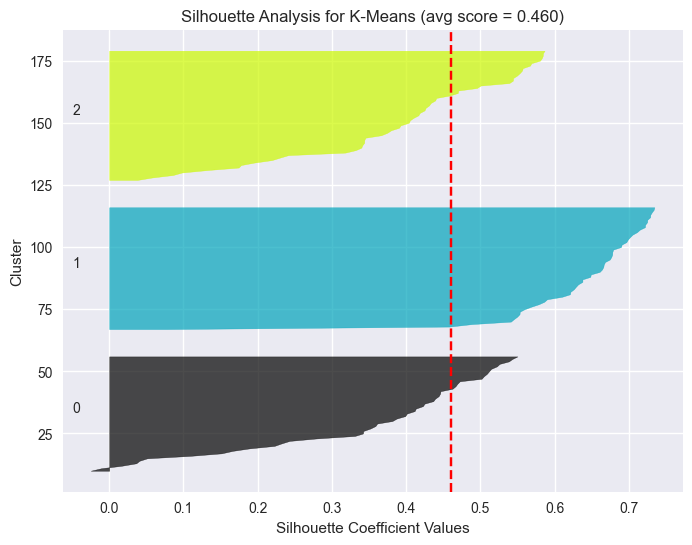

In [151]:
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm

# Apply K-Means
n_clusters = 3
clusterer = KMeans(n_clusters=n_clusters, random_state=123)
cluster_labels = clusterer.fit_predict(X_scaled)

# Compute silhouette scores
silhouette_avg = silhouette_score(X_scaled, cluster_labels)
sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)

print(f"Average Silhouette Score: {silhouette_avg:.3f}")

# Plot silhouette
plt.figure(figsize=(8,6))
y_lower = 10
for i in range(n_clusters):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / n_clusters)
    plt.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_silhouette_values,
                      facecolor=color, edgecolor=color, alpha=0.7)

    # Label the silhouette plot with cluster numbers
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    y_lower = y_upper + 10  # 10 for spacing

plt.axvline(x=silhouette_avg, color="red", linestyle="--")
plt.xlabel("Silhouette Coefficient Values")
plt.ylabel("Cluster")
plt.title(f"Silhouette Analysis for K-Means (avg score = {silhouette_avg:.3f})")
plt.show()

### **Silhouette Analysis plot for Each Cluster**

Average Silhouette Score: 0.460


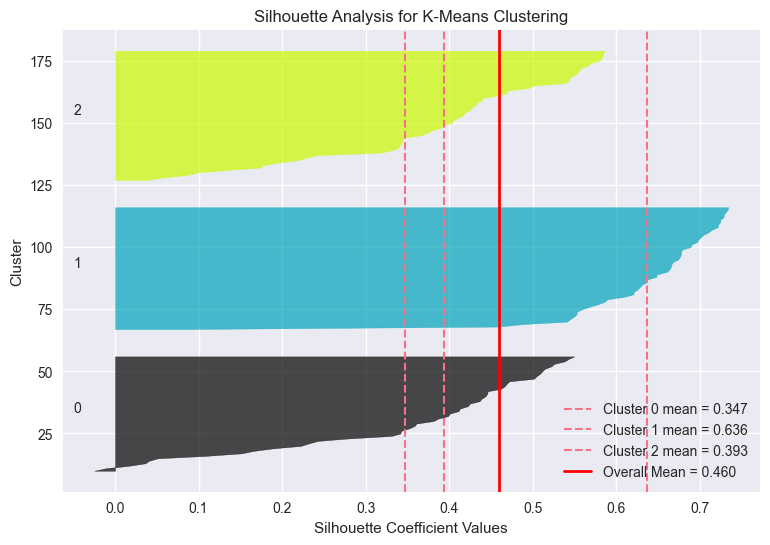

In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm

# Apply K-Means
n_clusters = 3
clusterer = KMeans(n_clusters=n_clusters, random_state=123)
cluster_labels = clusterer.fit_predict(X_scaled)

# Compute silhouette scores
silhouette_avg = silhouette_score(X_scaled, cluster_labels)
sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)

print(f"Average Silhouette Score: {silhouette_avg:.3f}")

plt.figure(figsize=(9,6))

y_lower = 10
cluster_means = []

for i in range(n_clusters):

    # Get silhouette values for cluster i
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / n_clusters)

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7
    )

    # Compute cluster mean silhouette
    cluster_mean = ith_cluster_silhouette_values.mean()
    cluster_means.append(cluster_mean)

    # Plot cluster-specific dashed line
    plt.axvline(x=cluster_mean, linestyle='--', linewidth=1.5,
                label=f'Cluster {i} mean = {cluster_mean:.3f}')

    # Cluster label
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    y_lower = y_upper + 10

# Global silhouette score
plt.axvline(x=silhouette_avg, color="red", linestyle="-", linewidth=2,
            label=f'Overall Mean = {silhouette_avg:.3f}')

plt.xlabel("Silhouette Coefficient Values")
plt.ylabel("Cluster")
plt.title("Silhouette Analysis for K-Means Clustering")
plt.legend()

plt.show()

### **PART II: CLUSTERING OF THE IRIS FLOWERS**

<div style='text-align:center;'>
  <img src="kmeans_iris.PNG" width="1200">
</div>

### **Load and prepare data**

In [136]:
iris = load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

### **Extract the Features Only**

In [137]:
X = iris.data  # Features only
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

### **Extract the Target Actual Labels**

In [138]:
y_true = iris.target  # True labels (for evaluation)
y_true

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

### **View the Features Names**

In [139]:
feature_names = iris.feature_names
feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

### **Scale the data (important for K-Means)**

In [142]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

### **Apply K-Means with k=3**
#### **Initialize the Model**

In [143]:
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=25, random_state=42)

### Fit the Model
kmeans_labels = kmeans.fit_predict(X_scaled)

# Results
print("Cluster Centers (scaled):")
print(kmeans.cluster_centers_)
print(f"\nTotal Within-Cluster Sum of Squares (WCSS): {kmeans.inertia_:.2f}")

Cluster Centers (scaled):
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]

Total Within-Cluster Sum of Squares (WCSS): 139.82


### **View the K-Means Labels**

In [144]:
kmeans_labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

The Iris dataset was analyzed using the K-Means clustering algorithm to identify natural groupings within the data. The dataset consists of four numerical features describing iris flowers: sepal length, sepal width, petal length, and petal width. To ensure comparability across features, the data was standardized using `StandardScaler`, which transformed the variables to have zero mean and unit variance. This step is critical since K-Means relies on Euclidean distances, which can be distorted by differing feature scales.

The K-Means algorithm was applied with **k = 3**, reflecting the known number of iris species. Cluster centers were obtained in the scaled feature space, indicating the average standardized feature values for each group. The centers highlight distinct patterns: one cluster with high petal dimensions, another with reduced sepal and petal sizes, and an intermediate cluster. These patterns correspond well to the species structure in the dataset.

The model’s compactness was evaluated using the **Within-Cluster Sum of Squares (WCSS)**, which was **139.82**. A lower WCSS indicates tighter, more homogeneous clusters. While not a definitive measure of accuracy, this value suggests reasonable clustering performance. Overall, K-Means successfully separated the iris samples into meaningful groups, providing insight into the dataset’s inherent structure.

### **Chooce the Optimal K-Clusters**

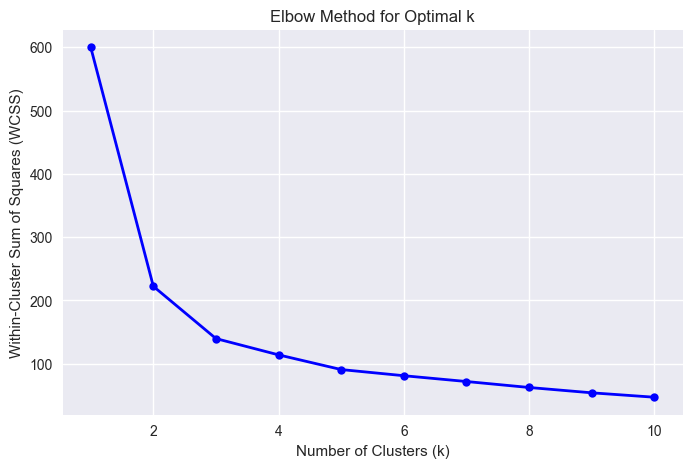

In [145]:
# Elbow method
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', n_init=25, random_state=123)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)
# Plot
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=6)
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

### **🎨 Visualize Clusters using PCA (2D Projection)**

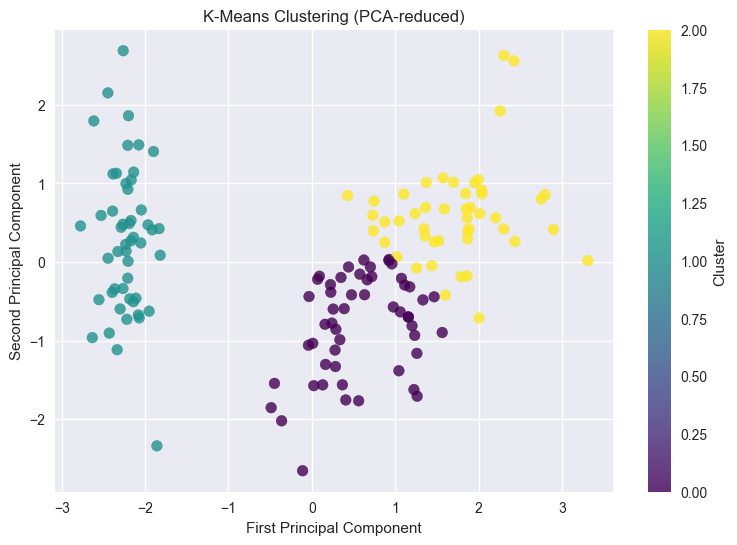

In [146]:
from sklearn.decomposition import PCA

# Reduce to 2D for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=60, alpha=0.8)
plt.colorbar(scatter, label='Cluster')
plt.title('K-Means Clustering (PCA-reduced)')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.grid(True)
plt.show()

### **Evaluate Clustering Performance**

In [147]:
y_true

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [148]:
kmeans_labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

In [149]:
# Internal metrics
sil_kmeans = silhouette_score(X_scaled, kmeans_labels)

# External metrics (if true labels available)
ari_kmeans = adjusted_rand_score(y_true, kmeans_labels)
nmi_kmeans = normalized_mutual_info_score(y_true, kmeans_labels)

print(f"Silhouette Score: {sil_kmeans:.3f}")
print(f"Adjusted Rand Index (ARI): {ari_kmeans:.3f}")
print(f"Normalized Mutual Info (NMI): {nmi_kmeans:.3f}")

Silhouette Score: 0.460
Adjusted Rand Index (ARI): 0.620
Normalized Mutual Info (NMI): 0.659


In [150]:
# =========================
# Internal Clustering Metrics
# =========================
sil_kmeans = silhouette_score(X_scaled, kmeans_labels)
dbi_kmeans = davies_bouldin_score(X_scaled, kmeans_labels)
ch_kmeans = calinski_harabasz_score(X_scaled, kmeans_labels)

# =========================
# External Metrics (require true labels)
# =========================
ari_kmeans = adjusted_rand_score(y_true, kmeans_labels)
nmi_kmeans = normalized_mutual_info_score(y_true, kmeans_labels)
homogeneity_kmeans = homogeneity_score(y_true, kmeans_labels)

# =========================
# Print Results
# =========================
print(f"Silhouette Score: {sil_kmeans:.3f}")
print(f"Davies-Bouldin Index: {dbi_kmeans:.3f}")
print(f"Calinski-Harabasz Score: {ch_kmeans:.3f}")

print(f"Adjusted Rand Index (ARI): {ari_kmeans:.3f}")
print(f"Normalized Mutual Info (NMI): {nmi_kmeans:.3f}")
print(f"Homogeneity Score: {homogeneity_kmeans:.3f}")

Silhouette Score: 0.460
Davies-Bouldin Index: 0.834
Calinski-Harabasz Score: 241.904
Adjusted Rand Index (ARI): 0.620
Normalized Mutual Info (NMI): 0.659
Homogeneity Score: 0.659


<div style='text-align:center;'>
  <img src="PCA.PNG" width="1200">
</div>

## **DIMENSIONALITY REDUCTION**

## **PRINCIPAL COMPONENT ANALYSIS (PCA)**

**Definition**

Principal Component Analysis (PCA) is a multivariate statistical technique used to reduce the dimensionality of a dataset while retaining as much information as possible. It transforms a large set of correlated variables into a smaller set of uncorrelated variables called **principal components**. PCA is widely used in data science, machine learning, bioinformatics, finance, healthcare, and social sciences for data exploration and visualization.

### **Objectives of PCA**

1. Reduce the number of variables in a dataset.
2. Remove multicollinearity among predictors.
3. Retain maximum variation present in the original data.
4. Simplify data interpretation and visualization.
5. Improve computational efficiency in predictive modeling.

### **How PCA Works**

PCA creates new variables known as principal components (PCs). These components are linear combinations of the original variables and are arranged according to the amount of variance they explain:

* **First Principal Component (PC1):** Captures the largest possible variance.
* **Second Principal Component (PC2):** Captures the second-largest variance and is orthogonal to PC1.
* Subsequent components explain progressively smaller amounts of variance.

The mathematical foundation of PCA is based on the decomposition of the covariance or correlation matrix through eigenvalues and eigenvectors.

### **Steps in PCA**

1. Standardize the data.
2. Compute the covariance/correlation matrix.
3. Calculate eigenvalues and eigenvectors.
4. Rank principal components by explained variance.
5. Select important components.
6. Transform the original data into the new component space.

### **Advantages of PCA**

* Reduces data complexity.
* Eliminates redundancy among variables.
* Facilitates visualization of high-dimensional data.
* Enhances machine learning model performance.

### **Limitations of PCA**

* Components may be difficult to interpret.
* Sensitive to scaling of variables.
* Assumes linear relationships among variables.

### **Conclusion**

PCA is a powerful unsupervised learning technique that summarizes large datasets into a few informative components while preserving most of the original variation. It serves as an essential tool for exploratory data analysis, feature extraction, and dimensionality reduction in modern statistical and machine learning applications.


### **Load the Needed Libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
from sklearn.model_selection import cross_val_score
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

### **Read the Data**

In [3]:
df =pd.read_csv("CVD_risk.csv")
df.head()

,Systolic_BP,Diastolic_BP,Total_Cholesterol,HDL_Cholesterol,Fasting_Glucose,CRP_Inflammation,Age,LDL_Cholesterol,CVD_Risk
0,0.633624,0.972012,0.533317,-0.729261,0.579548,0.666505,47.892110,0.213374,1
1,-0.294739,-0.153430,-0.440258,-0.075292,-0.872730,-1.010284,68.620717,-0.234435,0
2,0.813915,0.470587,0.766758,-0.536103,1.622474,0.449300,45.093939,0.569784,1
3,1.990625,1.144601,1.831485,-0.688583,1.955860,0.842074,40.329073,1.713434,1
4,-0.266326,-0.684938,0.456672,0.275218,0.307085,0.358382,39.738682,0.094073,0


### **EXPLORATORY DATA ANALYSIS & CORRELATION CHECK**

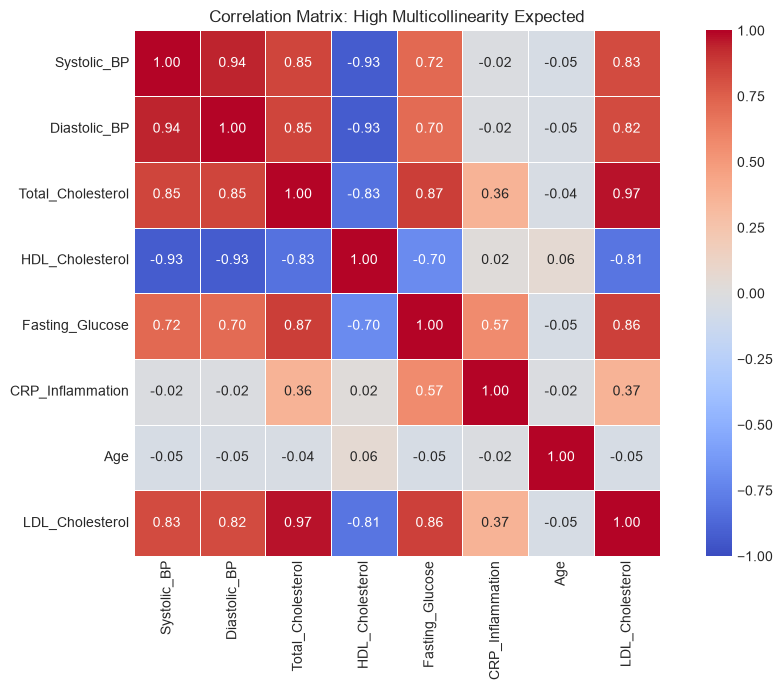

🔍 Observing high correlations (|r| > 0.7) among BP, Cholesterol, Glucose markers.
   PCA is ideal here to reduce redundancy and stabilize downstream models.



In [4]:
features = df.columns[:-1]
corr_matrix = df[features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            fmt='.2f', square=True, linewidths=0.5)
plt.title('Correlation Matrix: High Multicollinearity Expected')
plt.tight_layout()
plt.show()

print("🔍 Observing high correlations (|r| > 0.7) among BP, Cholesterol, Glucose markers.")
print("   PCA is ideal here to reduce redundancy and stabilize downstream models.\n")

### **PREPROCESSING & TRAIN/TEST SPLIT**

In [5]:
X = df[features].values
y = df['CVD_Risk'].values

### **Split BEFORE scaling to prevent data leakage**
This line of code beloww is splitting a dataset into training and testing subsets using the function `train_test_split()` from the machine learning library (commonly scikit-learn). The goal is to prepare data for building and evaluating a predictive model.

The input variables `X` and `y` represent the dataset features (independent variables) and the target variable (dependent variable), respectively. The function divides these into two parts: one for training the model and one for testing its performance.

The parameter `test_size=0.25` means that 25% of the entire dataset is set aside as the test set, while the remaining 75% is used for training. This allows the model to learn patterns from most of the data and then be evaluated on unseen data to assess generalization performance.

The `random_state=42` ensures reproducibility. It fixes the randomness in the splitting process so that every time the code is run, the same train-test split is obtained. This is important for consistent results during experimentation and reporting.

The `stratify=y` argument ensures that the proportion of classes in the target variable `y` is preserved in both the training and testing sets. This is especially important in classification problems where the dataset may be imbalanced. By maintaining the same class distribution, the model evaluation becomes more reliable and representative of real-world performance.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.25, 
    random_state=42, 
    stratify=y)

### **PCA is variance-sensitive → MUST standardize features**
This code performs feature standardization using the `StandardScaler` from scikit-learn, which is an important preprocessing step in many machine learning workflows.

First, `scaler = StandardScaler()` initializes the scaler object. This scaler will transform the data so that each feature has a mean of 0 and a standard deviation of 1.

Next, `X_train_scaled = scaler.fit_transform(X_train)` fits the scaler on the training data and transforms it at the same time. Fitting means it calculates the mean and standard deviation for each feature using only the training set, which prevents data leakage from the test set.

Then, `X_test_scaled = scaler.transform(X_test)` applies the same transformation to the test data using the parameters learned from the training data. This ensures consistency between training and testing distributions.

Finally, the print statement confirms that the data has been successfully split and standardized for model training.


In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Data split & standardized (mean=0, variance=1).")

✅ Data split & standardized (mean=0, variance=1).


### **PCA FITTING & COMPONENT SELECTION**
The code below is used to perform **Principal Component Analysis (PCA)** on the training dataset after it has been standardized. The objective is to identify how much variance each principal component explains before deciding how many components to retain for further analysis.

The first line creates a PCA object called `pca_full`. Since the number of components is not specified, PCA will compute **all possible principal components** from the dataset. The parameter `random_state=42` ensures reproducibility of results whenever randomness is involved.

The second line performs two operations simultaneously using the `fit_transform()` method. First, PCA is **fitted** to the standardized training data (`X_train_scaled`) by calculating the covariance structure of the variables and extracting the corresponding eigenvalues and eigenvectors. These eigenvectors define the directions of maximum variation in the data and become the principal components.

Second, the original standardized data is **transformed** into a new coordinate system defined by these principal components. The resulting matrix, `X_train_pca_full`, contains the scores of each observation on every principal component.

After fitting PCA on all components, researchers can examine attributes such as `explained_variance_ratio_` and cumulative explained variance to determine the optimal number of components to retain. This helps reduce dimensionality while preserving most of the information contained in the original variables, thereby improving visualization, reducing noise, and potentially enhancing machine learning model performance.


### **Fit PCA on ALL components first to evaluate variance explained**

In [9]:
pca_full = PCA(random_state=42)
X_train_pca_full = pca_full.fit_transform(X_train_scaled)
X_train_pca_full

array([[-0.11683563, -0.1982702 , -1.06913629, ...,  0.09654622,
        -0.01602333,  0.14320592],
       [ 1.39323022, -0.85986402,  0.55693229, ..., -0.54397165,
        -0.12627057, -0.17458266],
       [-0.12997117, -1.20182854, -1.03769044, ...,  0.61223156,
        -0.18257655, -0.01671955],
       ...,
       [-1.79967132, -0.41756346, -0.43129631, ..., -0.49128527,
         0.27558756,  0.09867719],
       [ 3.30610714, -0.57918996,  0.78883259, ...,  0.30296626,
         0.14274974,  0.13856119],
       [ 0.74896062,  1.75537434,  0.67313443, ..., -0.05719792,
         0.08138515,  0.05337818]], shape=(450, 8))

### **Explained Variance**
This code extracts and summarizes how much variance is explained by each principal component in a Principal Component Analysis (PCA) model.

The variable `explained_var = pca_full.explained_variance_ratio_` returns an array showing the proportion of the dataset’s total variance captured by each principal component. Each value indicates how important that component is in representing the original data.

Next, `cumulative_var = np.cumsum(explained_var)` computes the cumulative sum of these variance ratios using NumPy. This produces an array where each element shows the total variance explained up to that component.

Together, these metrics help decide how many principal components to retain while reducing dimensionality effectively.


In [10]:
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

In [11]:
cumulative_var

array([0.66205573, 0.82869684, 0.95236658, 0.9700104 , 0.98129349,
       0.99018687, 0.99715653, 1.        ])

### **Determine optimal components (e.g., 90% variance threshold)**
This code determines the optimal number of principal components to retain in PCA based on a chosen explained variance threshold.

First, `threshold = 0.90` sets the target level of total variance to be retained, meaning the goal is to preserve 90% of the information in the dataset.

Then, `n_components_opt = np.argmax(cumulative_var >= threshold) + 1` finds the first index where the cumulative explained variance reaches or exceeds 0.90. The `np.argmax()` function returns the position of the first True condition, and adding 1 adjusts for Python’s zero-based indexing. This gives the minimum number of components needed to reach the desired variance level.

Finally, the print statements display the explained variance for each component, the cumulative variance, and the optimal number of components. This helps in making an informed decision about dimensionality reduction while preserving most of the dataset’s information.


In [12]:
threshold = 0.90
n_components_opt = np.argmax(cumulative_var >= threshold) + 1

print(f"📊 Explained Variance per Component: {np.round(explained_var, 3)}")
print(f"📈 Cumulative Variance: {np.round(cumulative_var, 3)}")
print(f"🎯 Optimal Components for {threshold*100}% Variance: {n_components_opt}\n")

📊 Explained Variance per Component: [0.662 0.167 0.124 0.018 0.011 0.009 0.007 0.003]
📈 Cumulative Variance: [0.662 0.829 0.952 0.97  0.981 0.99  0.997 1.   ]
🎯 Optimal Components for 90.0% Variance: 3



### **VISUALIZATION**
This code visualizes the results of Principal Component Analysis (PCA) using two side-by-side plots to help interpret dimensionality reduction.

First, `fig, axes = plt.subplots(1, 2, figsize=(14, 5))` creates a figure with one row and two columns of subplots.

On the left, a Scree Plot is generated. The line `axes[0].plot(range(1, len(explained_var)+1), explained_var, 'bo-')` shows the variance explained by each individual principal component. Another line plots the cumulative explained variance (`cumulative_var`) in red. A horizontal green dashed line represents the selected variance threshold (e.g., 90%), while a vertical purple line marks the optimal number of components (`n_components_opt`). Labels, title, legend, and grid are added for clarity.

On the right, a 2D PCA projection is created using the first two principal components: `PCA(n_components=2)`. The transformed training data is plotted as a scatter plot, where points are colored based on the target variable `y_train` (e.g., cardiovascular disease risk). This helps visualize class separation in reduced dimensions.

Finally, `plt.tight_layout()` adjusts spacing for readability, and `plt.show()` displays both plots together.


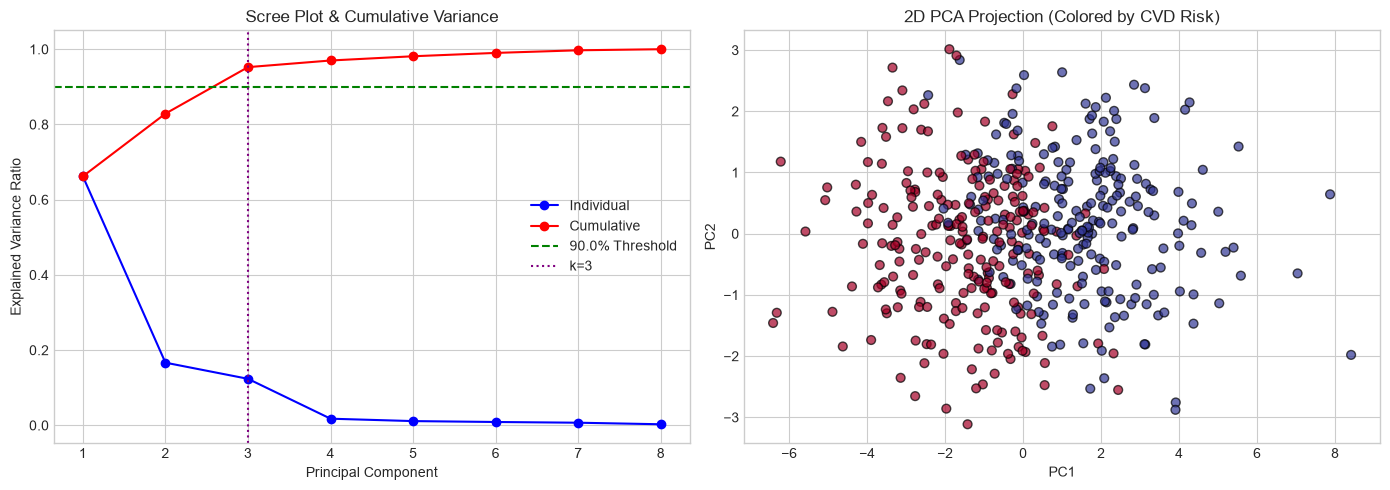

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree Plot
axes[0].plot(range(1, len(explained_var)+1), explained_var, 'bo-', label='Individual')
axes[0].plot(range(1, len(cumulative_var)+1), cumulative_var, 'ro-', label='Cumulative')
axes[0].axhline(y=threshold, color='g', linestyle='--', label=f'{threshold*100}% Threshold')
axes[0].axvline(x=n_components_opt, color='purple', linestyle=':', label=f'k={n_components_opt}')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot & Cumulative Variance')
axes[0].legend()
axes[0].grid(True)

# 2D Projection (PC1 vs PC2)
X_train_pca2 = PCA(n_components=2, random_state=42).fit_transform(X_train_scaled)
axes[1].scatter(X_train_pca2[:, 0], X_train_pca2[:, 1], c=y_train, cmap='RdYlBu',
                edgecolor='k', alpha=0.7, s=40)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('2D PCA Projection (Colored by CVD Risk)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### **COMPONENT INTERPRETATION (LOADINGS)**

In [15]:
# Final PCA with optimal components
pca_opt = PCA(n_components=n_components_opt, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_train_pca

array([[-0.11683563, -0.1982702 , -1.06913629],
       [ 1.39323022, -0.85986402,  0.55693229],
       [-0.12997117, -1.20182854, -1.03769044],
       ...,
       [-1.79967132, -0.41756346, -0.43129631],
       [ 3.30610714, -0.57918996,  0.78883259],
       [ 0.74896062,  1.75537434,  0.67313443]], shape=(450, 3))

In [16]:
X_test_pca = pca_opt.transform(X_test_scaled)
X_test_pca[:20]

array([[ 3.50731183, -0.44336942,  0.35738219],
       [ 0.05964431, -1.11073774,  0.43475438],
       [ 4.88145217,  1.03488993, -0.2760924 ],
       [ 5.15344968, -1.23066368, -0.4012044 ],
       [-2.58782076, -1.62369802,  1.42345819],
       [-4.55769608, -0.40346436,  0.50082036],
       [ 0.96194378,  0.0502663 ,  0.82571973],
       [-2.23939154,  0.12793142,  0.15186213],
       [ 1.90862566, -2.06560391, -0.85070363],
       [-2.08690331, -0.22849491,  0.10427585],
       [-3.70065367, -0.99185097,  1.2912706 ],
       [-1.42888745, -1.91503824, -0.65136306],
       [-2.64818373,  0.20733298, -0.95789233],
       [-2.73659844,  0.30405248, -1.60531547],
       [ 0.62932683, -0.03040546, -0.40593994],
       [-1.11446639,  1.245758  , -1.16790702],
       [-0.03220153,  0.31825378, -0.60104603],
       [-1.95771691,  0.46717988, -0.9726929 ],
       [-0.83380525, -1.2714864 ,  0.19493859],
       [-0.40279958, -1.61931506, -1.37926557]])

### **Components Loading**
This code computes and displays the PCA loadings, which describe how much each original feature contributes to each principal component in the reduced dataset.

First, `pca_opt.components_` contains the principal axes learned by the PCA model. Each row represents a principal component, and each column corresponds to a feature. The `.T` (transpose) is applied so that features become rows and components become columns, making the table easier to interpret in a feature-by-feature format.

Next, a pandas DataFrame called `loadings` is created. The columns are named dynamically as `PC1`, `PC2`, … up to the optimal number of components (`n_components_opt`). The index is set to `features`, which contains the original variable names (e.g., clinical or demographic variables).

The statement `print(loadings.round(3))` displays the loadings rounded to three decimal places for readability. These values indicate the strength and direction of each feature’s influence on a given principal component.

Finally, the printed interpretation notes explain that large absolute values (positive or negative) indicate that a feature strongly contributes to that component. This helps in understanding what each principal component represents conceptually, such as grouping related clinical variables together, and allows for meaningful interpretation of reduced-dimensional features in a machine learning context.


In [17]:
loadings = pd.DataFrame(
    pca_opt.components_.T,
    columns=[f'PC{i+1}' for i in range(n_components_opt)],
    index=features
)

print("📐 Component Loadings (Feature Weights in Each PC)")
print(loadings.round(3))
print("\n💡 Interpretation Tip: High absolute loading = feature strongly drives that PC.")
print("   You can rotate loadings to see which clinical constructs each PC represents.\n")

📐 Component Loadings (Feature Weights in Each PC)
                     PC1    PC2    PC3
Systolic_BP        0.403 -0.257  0.040
Diastolic_BP       0.403 -0.257  0.055
Total_Cholesterol  0.421  0.109  0.014
HDL_Cholesterol   -0.396  0.275 -0.027
Fasting_Glucose    0.387  0.316 -0.003
CRP_Inflammation   0.128  0.812 -0.070
Age               -0.044  0.089  0.995
LDL_Cholesterol    0.416  0.116 -0.002

💡 Interpretation Tip: High absolute loading = feature strongly drives that PC.
   You can rotate loadings to see which clinical constructs each PC represents.



This output shows the **PCA component loadings**, which explain how each original clinical feature contributes to the principal components (PCs). These loadings are essentially weights that indicate the strength and direction of influence of each variable in forming a component.

For **PC1**, the largest positive loadings come from Total Cholesterol (0.421), LDL Cholesterol (0.416), Systolic BP (0.403), Diastolic BP (0.403), and Fasting Glucose (0.387). HDL Cholesterol has a strong negative loading (-0.396). This suggests that PC1 represents a general **cardiometabolic risk factor axis**, where higher values correspond to worse cardiovascular risk profiles (higher blood pressure, cholesterol, and glucose, and lower protective HDL levels).

For **PC2**, the dominant feature is CRP Inflammation (0.812), indicating that this component mainly captures **systemic inflammation**. Moderate contributions from Fasting Glucose (0.316) and HDL Cholesterol (0.275) suggest a secondary relationship between metabolic dysregulation and inflammation. Blood pressure and LDL have smaller negative or weak effects here, meaning they are less influential in this component.

For **PC3**, Age has an extremely high loading (0.995), meaning this component is almost entirely driven by age. This suggests PC3 represents a **pure age-related dimension**, largely independent of biochemical markers.

The interpretation tip emphasizes that high absolute values (whether positive or negative) indicate strong influence. The sign only indicates direction, not importance. For example, HDL being negative in PC1 suggests it moves opposite to risk factors.

Overall, PCA has successfully reduced the dataset into interpretable hidden structures:
PC1 = cardiovascular/metabolic risk,
PC2 = inflammation-related variation,
PC3 = age-driven variation.

This transformation is useful for simplifying models, reducing multicollinearity, and improving machine learning performance while retaining meaningful clinical patterns.


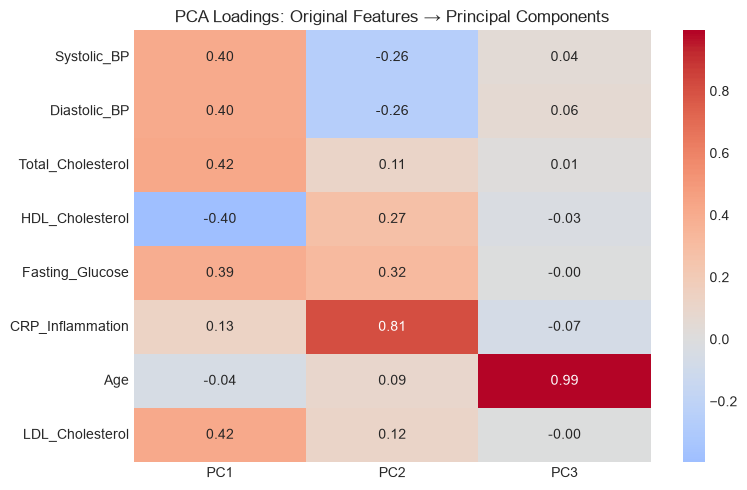

In [18]:
# Loading Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('PCA Loadings: Original Features → Principal Components')
plt.tight_layout()
plt.show()

### **MODEL EVALUATION: RAW vs PCA-TRANSFORMED FEATURES")**

### **A. Logistic Regression (Raw Scaled Features)**
This code is part of a model evaluation workflow where Logistic Regression is trained using the **original scaled features (raw feature space)**, before applying PCA transformation.

First, the line `model_raw = LogisticRegression(max_iter=1000, random_state=42)` initializes a Logistic Regression classifier. The parameter `max_iter=1000` increases the maximum number of iterations allowed for the optimization algorithm (used to find the best-fitting coefficients), ensuring convergence even for complex datasets. The `random_state=42` ensures reproducibility of results.

Next, `model_raw.fit(X_train_scaled, y_train)` trains the model using the standardized training data (`X_train_scaled`) and the corresponding target labels (`y_train`). During this step, the model learns relationships between the original features (such as blood pressure, cholesterol, glucose, and age) and the outcome variable (e.g., disease presence or risk category).

This baseline model is important because it provides a reference performance level before dimensionality reduction. Later, its accuracy, precision, recall, and other metrics can be compared with a PCA-based model to evaluate whether PCA improves performance, reduces overfitting, or enhances computational efficiency.


In [19]:
# Initializing the Model Fitting Process
model_raw = LogisticRegression(max_iter=1000, random_state=42)

# Fit model
model_raw.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### **Predictions**
This code evaluates the performance of the Logistic Regression model trained on **raw scaled features** by generating predictions and performing cross-validation.

First, `y_pred_raw = model_raw.predict(X_test_scaled)` produces the predicted class labels (e.g., 0 or 1) for the test dataset based on learned decision boundaries. These predictions are used for calculating classification metrics such as accuracy, precision, recall, and F1-score.

Next, `y_prob_raw = model_raw.predict_proba(X_test_scaled)[:, 1]` computes the predicted probabilities for the positive class (class 1). The `predict_proba()` function returns probabilities for all classes, and selecting `[:, 1]` extracts the likelihood of the positive outcome, which is useful for ROC curve analysis and AUC computation.

Then, cross-validation is performed using `cross_val_score()`. The first call computes **mean accuracy** across 5 folds (`cv=5`), giving a more robust estimate of model performance. The second computes **mean ROC-AUC**, which evaluates the model’s ability to distinguish between classes across different thresholds. These results help assess generalization and model stability.


In [20]:
y_pred_raw = model_raw.predict(X_test_scaled)
y_prob_raw = model_raw.predict_proba(X_test_scaled)[:, 1]

# Cross-validation
cv_acc_raw = cross_val_score(model_raw, X_train_scaled, y_train, cv=5, scoring='accuracy').mean()
cv_auc_raw = cross_val_score(model_raw, X_train_scaled, y_train, cv=5, scoring='roc_auc').mean()

### **Print results**

In [21]:
print("\n🔹 Logistic Regression (Raw Scaled Features)")
print(f"   Test Accuracy: {accuracy_score(y_test, y_pred_raw):.4f}")
print(f"   Test ROC-AUC : {roc_auc_score(y_test, y_prob_raw):.4f}")
print(f"   CV Accuracy  : {cv_acc_raw:.4f}")
print(f"   CV ROC-AUC   : {cv_auc_raw:.4f}")
print(classification_report(y_test, y_pred_raw, target_names=['Low Risk', 'High Risk']))



🔹 Logistic Regression (Raw Scaled Features)
   Test Accuracy: 0.8400
   Test ROC-AUC : 0.9252
   CV Accuracy  : 0.8600
   CV ROC-AUC   : 0.9452
              precision    recall  f1-score   support

    Low Risk       0.85      0.83      0.84        75
   High Risk       0.83      0.85      0.84        75

    accuracy                           0.84       150
   macro avg       0.84      0.84      0.84       150
weighted avg       0.84      0.84      0.84       150



### **B. Logistic Regression (PCA Features)**
This code trains a Logistic Regression model using PCA-transformed features, allowing comparison with the model trained on the original scaled dataset.

First, model_pca = LogisticRegression(max_iter=1000, random_state=42) initializes the Logistic Regression classifier. The parameter max_iter=1000 increases the number of iterations allowed for the optimization algorithm (such as LBFGS or SAG) to ensure convergence, especially when working with transformed feature spaces. The random_state=42 ensures that results are reproducible across different runs.

Next, model_pca.fit(X_train_pca, y_train) trains the model using the principal component scores (X_train_pca) instead of the original features. These PCA features are linear combinations of the original variables and are designed to capture most of the variance in fewer dimensions while reducing multicollinearity and noise.

This step is important because it allows evaluation of whether dimensionality reduction improves model performance. The PCA-based model may train faster, generalize better, or reduce overfitting, especially when the original dataset has correlated or redundant features. It also provides a simpler representation of the underlying data structure for classification.

In [22]:
# Initialzie Logistic Model Training Process
model_pca = LogisticRegression(max_iter=1000, random_state=42)

# Fit model
model_pca.fit(X_train_pca, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### **Predictions**

In [24]:
y_pred_pca = model_pca.predict(X_test_pca)
y_prob_pca = model_pca.predict_proba(X_test_pca)[:, 1]

# Cross-validation
cv_acc_pca = cross_val_score(model_pca, X_train_pca, y_train, cv=5, scoring='accuracy').mean()
cv_auc_pca = cross_val_score(model_pca, X_train_pca, y_train, cv=5, scoring='roc_auc').mean()

### **Print results**

In [25]:
print(f"\n🔹 Logistic Regression ({n_components_opt} PCA Components)")
print(f"   Test Accuracy: {accuracy_score(y_test, y_pred_pca):.4f}")
print(f"   Test ROC-AUC : {roc_auc_score(y_test, y_prob_pca):.4f}")
print(f"   CV Accuracy  : {cv_acc_pca:.4f}")
print(f"   CV ROC-AUC   : {cv_auc_pca:.4f}")
print(classification_report(y_test, y_pred_pca, target_names=['Low Risk', 'High Risk']))


🔹 Logistic Regression (3 PCA Components)
   Test Accuracy: 0.8533
   Test ROC-AUC : 0.9200
   CV Accuracy  : 0.8467
   CV ROC-AUC   : 0.9302
              precision    recall  f1-score   support

    Low Risk       0.87      0.83      0.85        75
   High Risk       0.84      0.88      0.86        75

    accuracy                           0.85       150
   macro avg       0.85      0.85      0.85       150
weighted avg       0.85      0.85      0.85       150



### **CONCLUSION AND COMPARISON**
This section compares the performance of a **Logistic Regression model trained on raw scaled features** versus one trained on **PCA-reduced features (3 principal components)**.

For the **raw scaled model**, the test accuracy is **0.8400**, meaning 84% of the test samples are correctly classified. The ROC-AUC score of **0.9252** indicates strong discriminatory ability between Low Risk and High Risk classes. Cross-validation results are slightly higher (Accuracy = **0.8600**, ROC-AUC = **0.9452**), showing that the model is relatively stable and generalizes well across different folds.

The classification report shows balanced performance across both classes. For Low Risk, precision is 0.85 and recall is 0.83, while for High Risk, precision is 0.83 and recall is 0.85. This symmetry suggests the model is not biased toward one class, which is important given equal class support (75 observations each).

For the **PCA-based model (3 components)**, performance improves slightly in accuracy to **0.8533**, indicating better generalization after dimensionality reduction. However, ROC-AUC slightly decreases to **0.9200**, suggesting a minor reduction in ranking performance. Cross-validation accuracy is **0.8467**, and CV ROC-AUC is **0.9302**, both still strong and comparable to the raw model.

The classification report shows improved recall for High Risk (0.88), meaning the PCA model is better at identifying high-risk individuals, which is often more important in healthcare applications. Precision remains strong (0.84–0.87 range), and overall F1-scores improve slightly to around 0.85–0.86.

Overall, the comparison shows that PCA reduces dimensionality from multiple correlated clinical variables into 3 components while maintaining or slightly improving predictive performance. The PCA model is more compact, computationally efficient, and still clinically meaningful. It demonstrates that most predictive information is captured in a few underlying structures (risk, inflammation, and age), making PCA a useful preprocessing step for simplified yet effective medical prediction models.
